In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    RocCurveDisplay,
    roc_auc_score
)

In [3]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Load dataset
df = pd.read_csv("../data/employee_attrition_clean.csv")

# Use the same features as Days 10–12
X = df.drop(columns=[
    "EmployeeID", "Attrition", "LastPromotionYears"
])
y = df["Attrition"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [4]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

evaluation_results = []

for name, clf in models.items():

    # Predictions
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )
    auc = roc_auc_score(y_test, y_prob)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "AUC": auc
    })

    print(f"\n{'=' * 40}")
    print(name)
    print("=" * 40)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

evaluation_df = pd.DataFrame(evaluation_results)

print("\nMODEL COMPARISON")
print(evaluation_df.round(3).to_string(index=False))


Logistic Regression

Confusion Matrix:
[[78 76]
 [20 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.51      0.62       154
           1       0.25      0.57      0.35        46

    accuracy                           0.52       200
   macro avg       0.53      0.54      0.49       200
weighted avg       0.67      0.52      0.56       200


Random Forest

Confusion Matrix:
[[119  35]
 [ 38   8]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.77      0.77       154
           1       0.19      0.17      0.18        46

    accuracy                           0.64       200
   macro avg       0.47      0.47      0.47       200
weighted avg       0.63      0.64      0.63       200


MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score   AUC
Logistic Regression     0.520      0.255   0.565     0.351 0.525
      Random Forest     0.635     

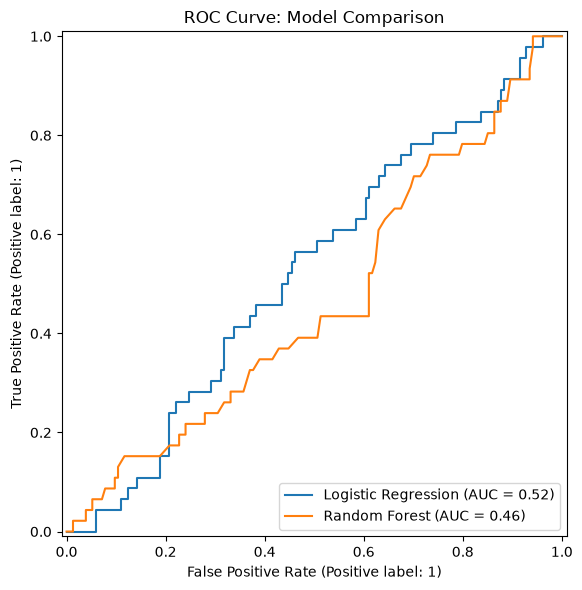

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, clf in models.items():
    RocCurveDisplay.from_estimator(
        clf,
        X_test,
        y_test,
        ax=ax,
        name=name
    )

ax.set_title("ROC Curve: Model Comparison")
plt.tight_layout()
plt.show()